X values 
', X.head().to_string(index=False)
Y values 
', Y.head().to_string(index=False)


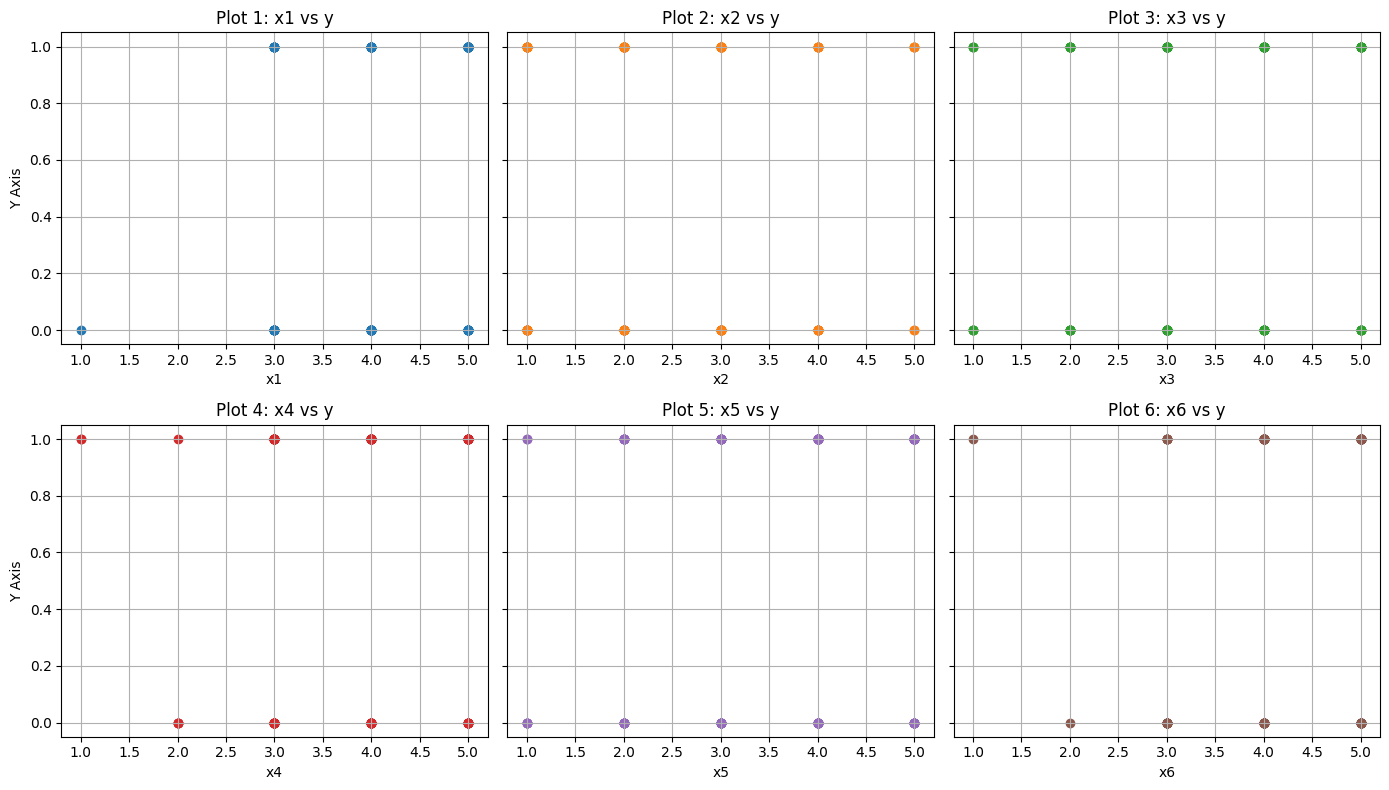

==========RESULTS FOR Logistic Regression======
Plotting ROC Curve for Logistic regression


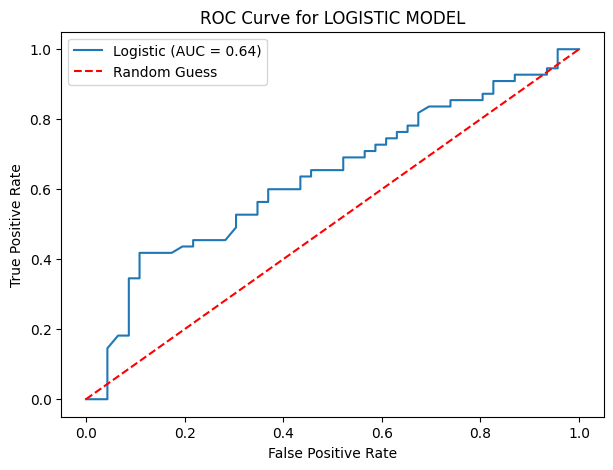

Generating Classification Report
Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.57      0.55        46
           1       0.62      0.60      0.61        55

    accuracy                           0.58       101
   macro avg       0.58      0.58      0.58       101
weighted avg       0.59      0.58      0.58       101

Plotting Precision Recall Curve for Logistic regression


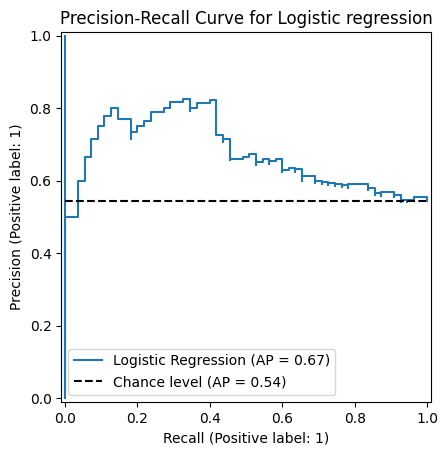

Baseline Accuracy (Default Params): 0.9000
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
==========RESULTS FOR RANDOM FORREST ======

--- Tuning Results ---
Best Hyperparameters Found: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 50}
Optimized Accuracy: 0.8833
Accuracy Improvement: -1.67%
==========RESULTS FOR RANDOM FORREST======
Plotting ROC Curve for RANDOM FORREST


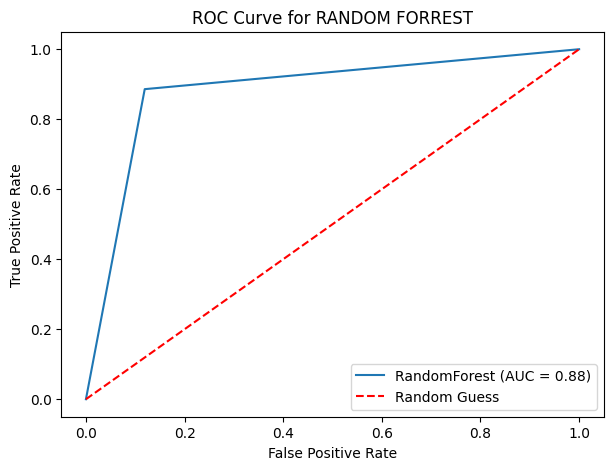

Generating Classification Report
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.88       151
           1       0.88      0.89      0.88       149

    accuracy                           0.88       300
   macro avg       0.88      0.88      0.88       300
weighted avg       0.88      0.88      0.88       300

Plotting Precision Recall Curve for Random forrest
Fitting 5 folds for each of 216 candidates, totalling 1080 fits


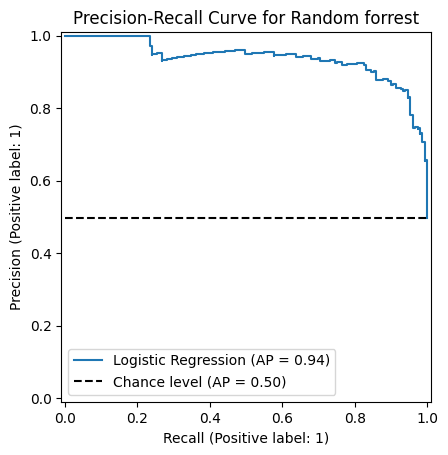

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, PrecisionRecallDisplay, roc_curve, auc, classification_report


# Read data====================================
data = pd.read_csv('HappinessSurvey2020.csv')
# split X and Y ============================ 
X = data.drop(columns=['Y'])
Y = data['Y']


# Print X and Y  values ======================================
print(f"X values \n', X.head().to_string(index=False)")
print(f"Y values \n', Y.head().to_string(index=False)")

# Extract X1, X2, X3, X4, X5, X6 ===========================
X1  = data[["X1"]]
X2  = data[["X2"]]
X3  = data[["X3"]]
X4  = data[["X4"]]
X5  = data[["X5"]]
X6  = data[["X6"]]
# Plot X, Y=======================================================
# Put the X data into a list for easy looping
x_data = [X1, X2, X3, X4, X5, X6]
labels = ["x1 vs y", "x2 vs y", "x3 vs y", "x4 vs y", "x5 vs y", "x6 vs y"]
#  Create a grid of subplots (2 rows, 3 columns to fit all 6 plots)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8), sharey=True)
# Flatten the 2D grid of axes to a 1D array so we can loop through it easily
axes = axes.flatten()
#  Loop through your data and plot each one individually
for i in range(6):
    axes[i].scatter(x_data[i], Y, label=labels[i], color=f"C{i}")
    axes[i].set_title(f"Plot {i+1}: {labels[i]}")
    axes[i].set_xlabel(f"x{i+1}")
    axes[i].grid(True)
# Set the shared Y-axis label on the leftmost plots
axes[0].set_ylabel("Y Axis")
axes[3].set_ylabel("Y Axis")
#  Clean up layout and display
plt.tight_layout()
plt.show()

# Split into training and testing sets (20%)==============================================
X_train, X_test, Y_train, Y_test = train_test_split( X, Y, random_state=42, test_size=0.8)
#========================================
#  LOGISTIC REGRESSION MODEL =============
#=======================================
logistic_model = LogisticRegression(random_state=42)
logistic_model.fit(X_train, Y_train)
##  Make predictions  for Linear regression using the test data
y_pred_logistic = logistic_model.predict_proba(X_test)[:, 1]
#Create Dataframe
test_df = pd.DataFrame({'True': Y_test, 'Logistic': y_pred_logistic})
# Plotting ROC Curve for Logistic regression
print("==========RESULTS FOR Logistic Regression======")
#  Receiver Operating Characteristic (ROC) curve
print("Plotting ROC Curve for Logistic regression")
plt.figure(figsize=(7, 5))
fpr, tpr, _ = roc_curve(test_df['True'], test_df['Logistic'])
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'{'Logistic'} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for LOGISTIC MODEL')
plt.legend()
plt.show()
#  Generating the Classification Report
y_pred_logistic1 = logistic_model.predict(X_test)
print("Generating Classification Report")
class_report = classification_report(Y_test, y_pred_logistic1)
print("Classification Report:")
print(class_report)
# Precision recall fro logistic regression
print("Plotting Precision Recall Curve for Logistic regression")
clf = LogisticRegression().fit(X_train, Y_train)
display = PrecisionRecallDisplay.from_estimator(clf, X_test, Y_test, name="Logistic Regression", plot_chance_level=True)
display.ax_.set_title("Precision-Recall Curve for Logistic regression")
plt.show()

########################################################################
##### RANDOM FORREST MODEL ===========================================
X, Y = make_classification(
    n_samples=1200, 
    n_features=20, 
    n_informative=15, 
    n_classes=2, 
    random_state=42
)

# Split into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split( X, Y, random_state=42)

# 2. Evaluate Baseline Model (Default Parameters)
baseline_rf = RandomForestClassifier(random_state=42)
baseline_rf.fit(X_train, Y_train)
baseline_preds = baseline_rf.predict(X_test)
baseline_accuracy = accuracy_score(Y_test, baseline_preds)

print(f"Baseline Accuracy (Default Params): {baseline_accuracy:.4f}")

# 3. Define the Hyperparameter Grid for Tuning
# We focus on the parameters that influence accuracy and overfitting the most:
param_grid = {
    'n_estimators': [50, 100, 200],       # Number of decision trees
    'max_depth': [None, 10, 20, 30],       # Maximum depth of the trees
    'min_samples_split': [2, 5, 10],       # Minimum samples needed to split a node
    'min_samples_leaf': [1, 2, 4],         # Minimum samples required at a leaf node
    'max_features': ['sqrt', 'log2']       # Number of features to consider at each split
}

# Initialize the Random Forest Base model
rf = RandomForestClassifier(random_state=42)

# 4. Use GridSearchCV to search for the best combinations using 5-fold cross-validation
# n_jobs=-1 uses all available processor cores to speed up training
grid_search = GridSearchCV(
    estimator=rf, 
    param_grid=param_grid, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1, 
    verbose=1
)

# Run the parameter tuning process
grid_search.fit(X_train, Y_train)

# 5. Extract Best Parameters and Calculate the New Accuracy
best_params = grid_search.best_params_
best_model = grid_search.best_estimator_

# Predict on test data using the tuned model
tuned_preds = best_model.predict(X_test)
tuned_accuracy = accuracy_score(Y_test, tuned_preds)
print("==========RESULTS FOR RANDOM FORREST ======")
print("\n--- Tuning Results ---")
print(f"Best Hyperparameters Found: {best_params}")
print(f"Optimized Accuracy: {tuned_accuracy:.4f}")
print(f"Accuracy Improvement: {(tuned_accuracy - baseline_accuracy) * 100:+.2f}%")

print("==========RESULTS FOR RANDOM FORREST======")
#Create Dataframe
test_rf = pd.DataFrame({'True': Y_test, 'RandomForest': tuned_preds})
print("Plotting ROC Curve for RANDOM FORREST")
plt.figure(figsize=(7, 5))
fpr, tpr, _ = roc_curve(test_rf['True'], test_rf['RandomForest'])
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'{'RandomForest'} (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'r--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for RANDOM FORREST')
plt.legend()
plt.show()
#  Generating the Classification Report
print("Generating Classification Report")
class_report1 = classification_report(Y_test, tuned_preds)
print("Classification Report:")
print(class_report1)

# Precision recall for Random forrest
print("Plotting Precision Recall Curve for Random forrest")
rf1=grid_search.fit(X_train, Y_train)
display = PrecisionRecallDisplay.from_estimator(rf1, X_test, Y_test, name="Logistic Regression", plot_chance_level=True)
display.ax_.set_title("Precision-Recall Curve for Random forrest")
plt.show()
